## 1. Exploración de Datos

In [1]:
import io
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
def procesar_imagen(bytes_img):
    im = Image.open(io.BytesIO(bytes_img)).convert('RGB')
    im = im.resize((20, 20), Image.BILINEAR)
    return np.asarray(im, dtype=np.float32).ravel()

df = pd.read_parquet('../LAB5/dataset/train.parquet')
print(f"Registros: {df.shape[0]}, Clases: {df['label'].nunique()}")

X = np.stack(df['image'].map(lambda d: procesar_imagen(d['bytes'])))
y = df['label'].values.astype(np.int64)

mu = X.mean(axis=0)
sigma = X.std(axis=0)
sigma[sigma == 0] = 1
X = (X - mu) / sigma

print(f"X shape: {X.shape}")

Registros: 100000, Clases: 200
X shape: (100000, 1200)


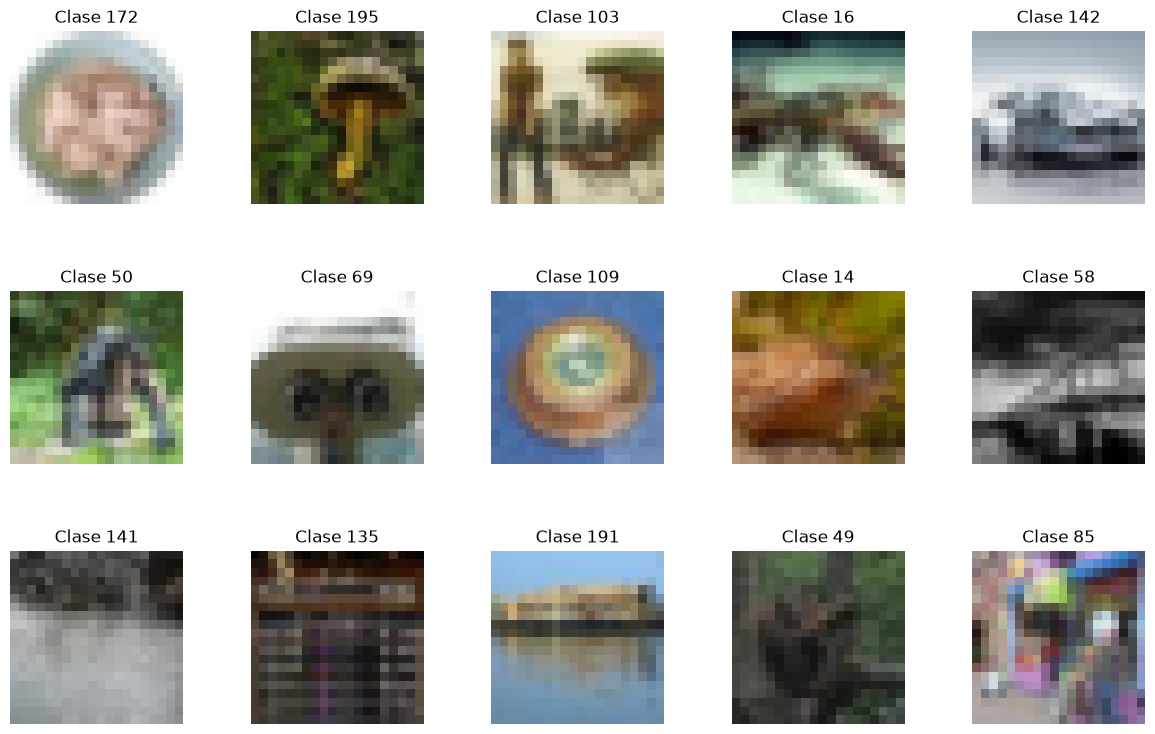

In [3]:
r, c = 3, 5
plt.figure(figsize=(c*3, r*3))
for row in range(r):
    for col in range(c):
        index = c*row + col
        plt.subplot(r, c, index + 1)
        ix = random.randint(0, len(X)-1)
        img = (X[ix] * sigma + mu).reshape(20, 20, 3).astype(np.uint8)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Clase {y[ix]}")
plt.subplots_adjust(wspace=0.2, hspace=0.5)
plt.show()

In [4]:
print(f"Max global: {X.max():.2f}, Min global: {X.min():.2f}")

Max global: 2.91, Min global: -2.23


Clases: 200, Ejemplos por clase: 500


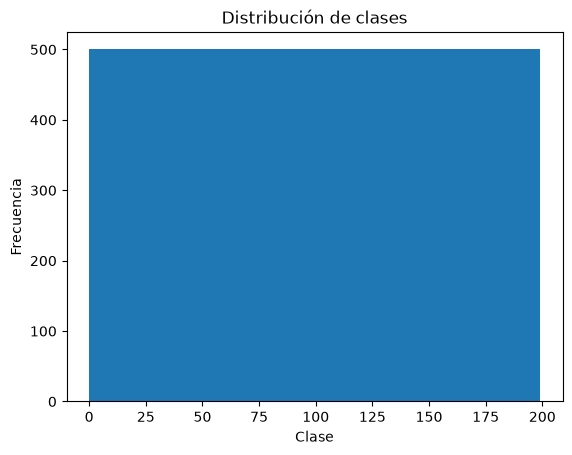

In [5]:
unique, counts = np.unique(y, return_counts=True)
print(f"Clases: {len(unique)}, Ejemplos por clase: {counts[0]}")
plt.hist(y, bins=len(unique))
plt.xlabel('Clase')
plt.ylabel('Frecuencia')
plt.title('Distribución de clases')
plt.show()

## 2. División de datos

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.125, stratify=y_train, random_state=42
)
print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")

X_subset, y_subset = X_train[:5000], y_train[:5000]
print(f"Subset: {X_subset.shape[0]}")

Train: 70000 | Val: 10000 | Test: 20000
Subset: 5000


## 3. Dataset y DataLoader

In [7]:
class Dataset(torch.utils.data.Dataset):
    def __init__(self, X, Y):
        self.X = torch.from_numpy(X).float().to(device)
        self.Y = torch.from_numpy(Y).long().to(device)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, ix):
        return self.X[ix], self.Y[ix]

## 4. Modelo

In [8]:
D_in = X.shape[1]   # 1200 (20*20*3)
D_out = df['label'].nunique()  # 200

def build_model(D_in=D_in, H=256, D_out=D_out):
    return torch.nn.Sequential(
        torch.nn.Linear(D_in, H),
        torch.nn.BatchNorm1d(H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, H),
        torch.nn.BatchNorm1d(H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, D_out)
    ).to(device)

## 5. Validación de la red neuronal

### Test de dimensiones

In [9]:
model = build_model()
test_input = torch.randn((64, D_in)).to(device)
test_output = model(test_input)
print(f"Entrada: {test_input.shape} → Salida: {test_output.shape}")
assert test_output.shape == (64, D_out), "¡Dimensiones incorrectas!"
print("✓ Dimensiones correctas")

Entrada: torch.Size([64, 1200]) → Salida: torch.Size([64, 200])
✓ Dimensiones correctas


### Fit de una muestra

In [10]:
dataset = Dataset(X_subset[:8], y_subset[:8])
dataloader = torch.utils.data.DataLoader(dataset, batch_size=8)

epochs = 5
criterion = torch.nn.CrossEntropyLoss()
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
print("--- Fit de una muestra ---")
for e in range(1, epochs+1):
    model.train()
    for x_b, y_b in dataloader:
        y_pred = model(x_b)
        loss = criterion(y_pred, y_b)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        print(f"Epoch {e}/{epochs} loss {loss.item():.5f} y {y_b[0].item()} y_pred {torch.argmax(y_pred[0], axis=0).item()}")

--- Fit de una muestra ---
Epoch 1/5 loss 5.48841 y 196 y_pred 125
Epoch 2/5 loss 2.48907 y 196 y_pred 196
Epoch 3/5 loss 0.56805 y 196 y_pred 196
Epoch 4/5 loss 0.13114 y 196 y_pred 196
Epoch 5/5 loss 0.03939 y 196 y_pred 196


### Fit de un batch

In [11]:
dataset = Dataset(X_subset[:64], y_subset[:64])
dataloader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=True)

epochs = 200
criterion = torch.nn.CrossEntropyLoss()
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
print("--- Fit de un batch ---")
for e in range(1, epochs+1):
    for x_b, y_b in dataloader:
        y_pred = model(x_b)
        loss = criterion(y_pred, y_b)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        acc = (y_b == torch.argmax(y_pred, axis=1)).sum().item()
        if not e % 10:
            print(f"Epoch {e}/{epochs} loss {loss.item():.5f} acc {acc}/{y_b.shape[0]}")

--- Fit de un batch ---
Epoch 10/200 loss 0.04087 acc 64/64
Epoch 20/200 loss 0.00179 acc 64/64
Epoch 30/200 loss 0.00047 acc 64/64
Epoch 40/200 loss 0.00025 acc 64/64
Epoch 50/200 loss 0.00018 acc 64/64
Epoch 60/200 loss 0.00015 acc 64/64
Epoch 70/200 loss 0.00013 acc 64/64
Epoch 80/200 loss 0.00012 acc 64/64
Epoch 90/200 loss 0.00011 acc 64/64
Epoch 100/200 loss 0.00010 acc 64/64
Epoch 110/200 loss 0.00010 acc 64/64
Epoch 120/200 loss 0.00009 acc 64/64
Epoch 130/200 loss 0.00009 acc 64/64
Epoch 140/200 loss 0.00008 acc 64/64
Epoch 150/200 loss 0.00008 acc 64/64
Epoch 160/200 loss 0.00007 acc 64/64
Epoch 170/200 loss 0.00007 acc 64/64
Epoch 180/200 loss 0.00007 acc 64/64
Epoch 190/200 loss 0.00006 acc 64/64
Epoch 200/200 loss 0.00006 acc 64/64


## 6. Funciones de entrenamiento

In [12]:
def softmax(x):
    return torch.exp(x) / torch.exp(x).sum(axis=-1, keepdims=True)

def fit(model, dataloader, optimizer, scheduler=None, epochs=10, log_each=1, weight_decay=0, early_stopping=0, verbose=1):
    criterion = torch.nn.CrossEntropyLoss()
    l, acc, lr = [], [], []
    val_l, val_acc = [], []
    best_acc, step = 0, 0
    for e in range(1, epochs+1):
        _l, _acc = [], []
        for param_group in optimizer.param_groups:
            lr.append(param_group['lr'])
        model.train()
        for x_b, y_b in dataloader['train']:
            y_pred = model(x_b)
            loss = criterion(y_pred, y_b)
            _l.append(loss.item())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            y_probas = torch.argmax(softmax(y_pred), axis=1)
            _acc.append(accuracy_score(y_b.cpu().numpy(), y_probas.cpu().detach().numpy()))
        l.append(np.mean(_l))
        acc.append(np.mean(_acc))
        model.eval()
        _l, _acc = [], []
        with torch.no_grad():
            for x_b, y_b in dataloader['val']:
                y_pred = model(x_b)
                loss = criterion(y_pred, y_b)
                _l.append(loss.item())
                y_probas = torch.argmax(softmax(y_pred), axis=1)
                _acc.append(accuracy_score(y_b.cpu().numpy(), y_probas.cpu().numpy()))
        val_l.append(np.mean(_l))
        val_acc.append(np.mean(_acc))
        if val_acc[-1] > best_acc:
            best_acc = val_acc[-1]
            torch.save(model.state_dict(), 'ckpt.pt')
            step = 0
            if verbose == 2:
                print(f"Mejor modelo guardado con acc {best_acc:.5f} en epoch {e}")
        step += 1
        if scheduler:
            scheduler.step()
        if early_stopping and step > early_stopping:
            print(f"Entrenamiento detenido en epoch {e} por no mejorar en {early_stopping} epochs seguidas")
            break
        if not e % log_each and verbose:
            print(f"Epoch {e}/{epochs} loss {l[-1]:.5f} acc {acc[-1]:.5f} val_loss {val_l[-1]:.5f} val_acc {val_acc[-1]:.5f} lr {lr[-1]:.5f}")
    model.load_state_dict(torch.load('ckpt.pt'))
    return {'epoch': list(range(1, len(l)+1)), 'loss': l, 'acc': acc, 'val_loss': val_l, 'val_acc': val_acc, 'lr': lr}

## 7. Entrenamiento con subconjunto de datos

In [13]:
dataset = {
    'train': Dataset(X_subset, y_subset),
    'val': Dataset(X_val, y_val),
}

dataloader = {
    'train': torch.utils.data.DataLoader(dataset['train'], batch_size=64, shuffle=True),
    'val': torch.utils.data.DataLoader(dataset['val'], batch_size=1000, shuffle=False)
}

print(f"Train: {len(dataset['train'])} | Val: {len(dataset['val'])}")

Train: 5000 | Val: 10000


### Búsqueda de learning rate

In [14]:
lrs = [0.001, 0.0005, 0.0001]
hists = []
for lr in lrs:
    print(f"\nProbando lr {lr}")
    model = build_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = fit(model, dataloader, optimizer, epochs=10, verbose=0)
    hists.append(hist)


Probando lr 0.001

Probando lr 0.0005

Probando lr 0.0001


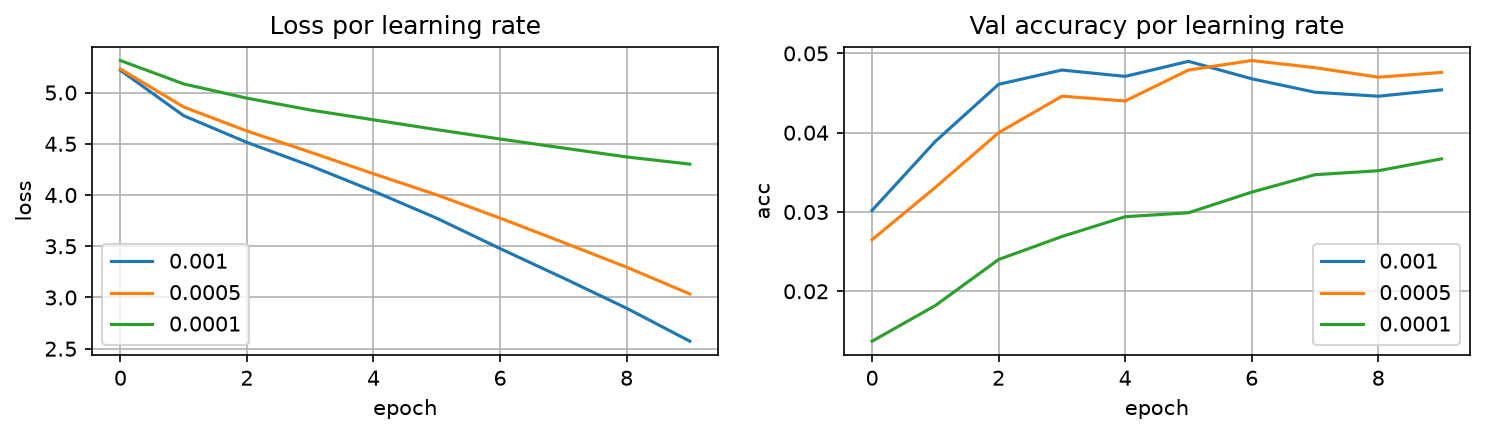

In [15]:
fig = plt.figure(dpi=150, figsize=(10, 3))
ax = plt.subplot(121)
for i in range(len(lrs)):
    ax.plot(hists[i]['loss'], label=lrs[i])
ax.legend()
ax.grid(True)
ax.set_xlabel('epoch')
ax.set_ylabel('loss')
ax.set_title('Loss por learning rate')
ax = plt.subplot(122)
for i in range(len(lrs)):
    ax.plot(hists[i]['val_acc'], label=lrs[i])
ax.legend()
ax.grid(True)
ax.set_ylabel('acc')
ax.set_xlabel('epoch')
ax.set_title('Val accuracy por learning rate')
plt.tight_layout()
plt.show()

### Búsqueda de batch size

In [16]:
bss = [32, 64, 128, 256]
hists = []
for bs in bss:
    print(f"\nProbando bs {bs}")
    dl = {
        'train': torch.utils.data.DataLoader(dataset['train'], batch_size=bs, shuffle=True),
        'val': torch.utils.data.DataLoader(dataset['val'], batch_size=1000, shuffle=False)
    }
    model = build_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    hist = fit(model, dl, optimizer, epochs=10, verbose=0)
    hists.append(hist)


Probando bs 32

Probando bs 64

Probando bs 128

Probando bs 256


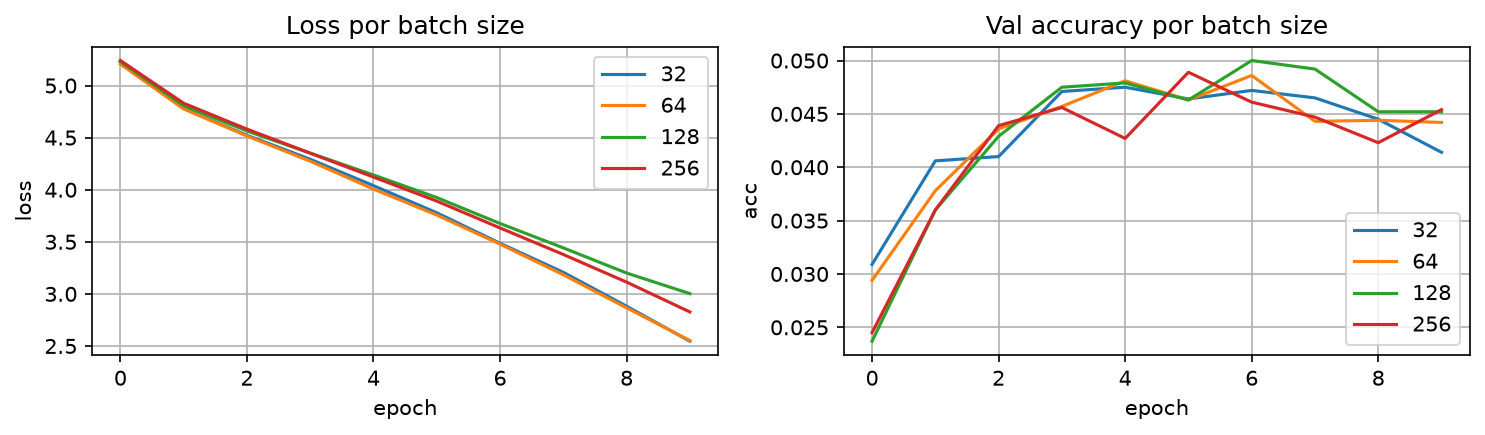

In [17]:
fig = plt.figure(dpi=150, figsize=(10, 3))
ax = plt.subplot(121)
for i in range(len(bss)):
    ax.plot(hists[i]['loss'], label=bss[i])
ax.legend()
ax.grid(True)
ax.set_xlabel('epoch')
ax.set_ylabel('loss')
ax.set_title('Loss por batch size')
ax = plt.subplot(122)
for i in range(len(bss)):
    ax.plot(hists[i]['val_acc'], label=bss[i])
ax.legend()
ax.grid(True)
ax.set_ylabel('acc')
ax.set_xlabel('epoch')
ax.set_title('Val accuracy por batch size')
plt.tight_layout()
plt.show()

### Búsqueda aleatoria de hiperparámetros

In [18]:
import random

bss = [32, 64, 128, 256]
lrs = [0.001, 0.0005, 0.0003, 0.0001]
n = 5
hists = []
for i in range(n):
    lr = random.choice(lrs)
    bs = random.choice(bss)
    print(f"\nTest {i+1} lr {lr} bs {bs}")
    dl = {
        'train': torch.utils.data.DataLoader(dataset['train'], batch_size=bs, shuffle=True),
        'val': torch.utils.data.DataLoader(dataset['val'], batch_size=1000, shuffle=False)
    }
    model = build_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = fit(model, dl, optimizer, epochs=20, verbose=0)
    hists.append({'hist': hist, 'lr': lr, 'bs': bs})


Test 1 lr 0.0005 bs 64

Test 2 lr 0.001 bs 64

Test 3 lr 0.0001 bs 64

Test 4 lr 0.0003 bs 256

Test 5 lr 0.0001 bs 256


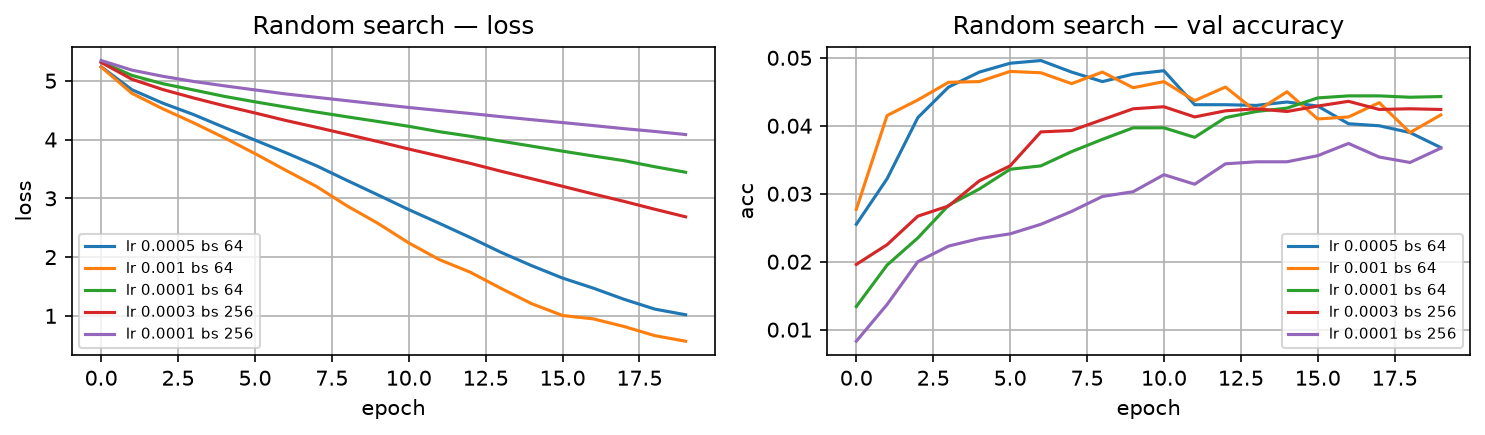

In [19]:
fig = plt.figure(dpi=150, figsize=(10, 3))
ax = plt.subplot(121)
for i in range(len(hists)):
    ax.plot(hists[i]['hist']['loss'], label=f'lr {hists[i]["lr"]} bs {hists[i]["bs"]}')
ax.legend(fontsize=7)
ax.grid(True)
ax.set_xlabel('epoch')
ax.set_ylabel('loss')
ax.set_title('Random search — loss')
ax = plt.subplot(122)
for i in range(len(hists)):
    ax.plot(hists[i]['hist']['val_acc'], label=f'lr {hists[i]["lr"]} bs {hists[i]["bs"]}')
ax.legend(fontsize=7)
ax.grid(True)
ax.set_ylabel('acc')
ax.set_xlabel('epoch')
ax.set_title('Random search — val accuracy')
plt.tight_layout()
plt.show()

## 8. Entrenamiento final

In [20]:
dataset = {
    'train': Dataset(X_train, y_train),
    'val': Dataset(X_val, y_val),
}

dataloader = {
    'train': torch.utils.data.DataLoader(dataset['train'], batch_size=64, shuffle=True),
    'val': torch.utils.data.DataLoader(dataset['val'], batch_size=1000, shuffle=False)
}

print(f"Train: {len(dataset['train'])} | Val: {len(dataset['val'])}")

Train: 70000 | Val: 10000


In [21]:
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, 20, 0.1)
hist = fit(model, dataloader, optimizer, scheduler, epochs=100, early_stopping=10, verbose=2)

Mejor modelo guardado con acc 0.07540 en epoch 1
Epoch 1/100 loss 4.74407 acc 0.05580 val_loss 4.52032 val_acc 0.07540 lr 0.00100
Mejor modelo guardado con acc 0.09290 en epoch 2
Epoch 2/100 loss 4.42040 acc 0.09033 val_loss 4.39724 val_acc 0.09290 lr 0.00100
Mejor modelo guardado con acc 0.10550 en epoch 3
Epoch 3/100 loss 4.26000 acc 0.10860 val_loss 4.30789 val_acc 0.10550 lr 0.00100
Mejor modelo guardado con acc 0.11040 en epoch 4
Epoch 4/100 loss 4.13321 acc 0.12789 val_loss 4.27793 val_acc 0.11040 lr 0.00100
Mejor modelo guardado con acc 0.11850 en epoch 5
Epoch 5/100 loss 4.02734 acc 0.14157 val_loss 4.24432 val_acc 0.11850 lr 0.00100
Mejor modelo guardado con acc 0.12040 en epoch 6
Epoch 6/100 loss 3.92735 acc 0.15535 val_loss 4.24151 val_acc 0.12040 lr 0.00100
Mejor modelo guardado con acc 0.12740 en epoch 7
Epoch 7/100 loss 3.83708 acc 0.16843 val_loss 4.25656 val_acc 0.12740 lr 0.00100
Epoch 8/100 loss 3.75064 acc 0.17980 val_loss 4.27184 val_acc 0.12080 lr 0.00100
Epoch 9/1

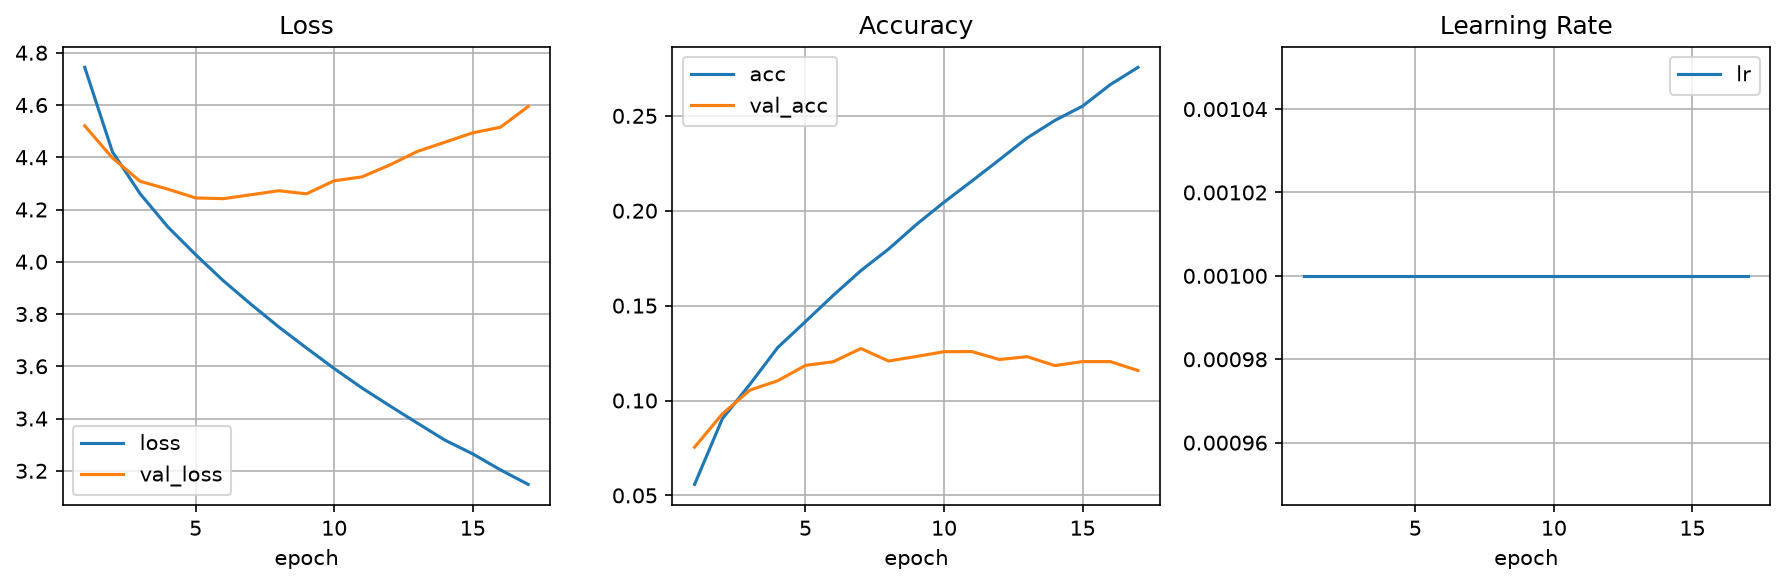

In [22]:
fig = plt.figure(dpi=150, figsize=(12, 4))
ax = plt.subplot(131)
pd.DataFrame(hist).plot(x='epoch', y=['loss', 'val_loss'], grid=True, ax=ax)
ax.set_title('Loss')
ax = plt.subplot(132)
pd.DataFrame(hist).plot(x='epoch', y=['acc', 'val_acc'], grid=True, ax=ax)
ax.set_title('Accuracy')
ax = plt.subplot(133)
pd.DataFrame(hist).plot(x='epoch', y=['lr'], grid=True, ax=ax)
ax.set_title('Learning Rate')
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Evaluación en test

In [23]:
dataset_test = Dataset(X_test, y_test)
dataloader_test = torch.utils.data.DataLoader(dataset_test, batch_size=1000, shuffle=False)

model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x_b, y_b in dataloader_test:
        preds = model(x_b.to(device))
        preds = torch.argmax(preds, axis=1)
        y_true.extend(y_b.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

acc = accuracy_score(y_true, y_pred)
print(f"\n[Test] Accuracy = {acc:.4f}")


[Test] Accuracy = 0.1240


In [24]:
from sklearn.metrics import classification_report

print("\nReporte de clasificación (primeras 20 clases):")
unique_labels = sorted(set(y_true))
target_names = [str(i) for i in unique_labels[:20]]
print(classification_report(y_true, y_pred, labels=unique_labels[:20], target_names=target_names))


Reporte de clasificación (primeras 20 clases):
              precision    recall  f1-score   support

           0       0.22      0.26      0.24       100
           1       0.17      0.09      0.12       100
           2       0.14      0.15      0.15       100
           3       0.06      0.09      0.07       100
           4       0.06      0.13      0.08       100
           5       0.25      0.01      0.02       100
           6       0.11      0.09      0.10       100
           7       0.08      0.03      0.04       100
           8       0.18      0.22      0.20       100
           9       0.29      0.07      0.11       100
          10       0.10      0.07      0.08       100
          11       0.09      0.21      0.12       100
          12       0.32      0.53      0.40       100
          13       0.14      0.19      0.16       100
          14       0.14      0.02      0.04       100
          15       0.19      0.14      0.16       100
          16       0.15      0.13

## 10. Guardar y cargar modelo

In [25]:
PATH = './checkpoint_final.pt'
torch.save(model.state_dict(), PATH)
print(f"Pesos guardados en: {PATH}")

Pesos guardados en: ./checkpoint_final.pt


In [26]:
model_loaded = build_model()
model_loaded.load_state_dict(torch.load(PATH))
model_loaded.eval()

with torch.no_grad():
    x_sample = torch.from_numpy(X_test[:10]).float().to(device)
    preds = torch.argmax(model_loaded(x_sample), axis=1).cpu().numpy()
    print("\nPredicciones sobre las primeras 10 muestras de prueba:")
    for i in range(10):
        print(f"  Real: {y_test[i]} | Predicho: {preds[i]}")


Predicciones sobre las primeras 10 muestras de prueba:
  Real: 55 | Predicho: 55
  Real: 0 | Predicho: 0
  Real: 55 | Predicho: 55
  Real: 171 | Predicho: 80
  Real: 44 | Predicho: 44
  Real: 60 | Predicho: 64
  Real: 45 | Predicho: 128
  Real: 43 | Predicho: 62
  Real: 15 | Predicho: 100
  Real: 29 | Predicho: 143
